In [1]:
import pandas as pd
import numpy as np

sample_meta = pd.read_csv('./metadata_files/master_sample_metadata_111226.csv')
peps_meta = pd.read_csv('./metadata_files/lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')
peps_metadata = peps_meta.set_index('seq_id')


df= pd.read_csv('./output_files/long_spec_0_98_111226.csv')


In [2]:
df_lassa = df.loc[df['species'] == 'Mammarenavirus lassaense']

In [3]:
lassa_max_per_protein = df_lassa.groupby(['protein_std', 'individual'])['z_score'].max().reset_index()

In [4]:
lassa_max_wide = lassa_max_per_protein.pivot_table(values='z_score', index='protein_std', columns='individual')

In [5]:
n_reactive_proteins = (
    df[
        (df['species'] == 'Mammarenavirus lassaense') & 
        (df['reactive'] == True)
    ]
    .groupby('individual')['protein_std']
    .nunique()
)

passing_individuals = n_reactive_proteins[n_reactive_proteins >= 3].index

#everyone else fails
failing_individuals = lassa_max_wide.columns.difference(passing_individuals)

print("Passing", len(passing_individuals))
print("Failing", len(failing_individuals))

#keep everyone, but set failing individuals to zero
lassa_max_wide_filtered = lassa_max_wide.copy()
lassa_max_wide_filtered.loc[:, failing_individuals] = 0

Passing 266
Failing 218


In [6]:
passing_individuals.to_series().to_csv('./output_files/passing_individuals_pep_reactive_min_3_lasv_proteins.csv', index=False, header=['individual'])

### Repeat matrix showing max z score for each protein across the cohort with the condition that peptides from at least 2 LASV proteins need to be reactive

In [7]:
c_cols = lassa_max_wide_filtered.filter(regex='C-').columns
s_cols = lassa_max_wide_filtered.filter(regex='S-').columns
hbdb_cols = lassa_max_wide_filtered.filter(regex='HBDB').columns

In [8]:
lassa_max_wide_filtered = lassa_max_wide_filtered.loc[:, list(c_cols) + list(s_cols) + list(hbdb_cols)]

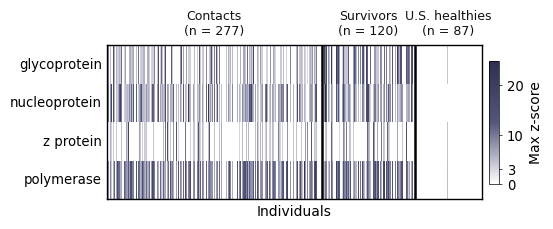

In [9]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from fig_style import apply_style

apply_style()

TEXT_COLOR = "#111111"

cmap = sns.light_palette("#2E3050", as_cmap=True)

# Group sizes / labels (rename to match your study)
groups = [
    ("Contacts",   len(c_cols)),
    ("Survivors",  len(s_cols)),
    ("U.S. healthies", len(hbdb_cols)),
]

fig, ax = plt.subplots(figsize=(5.8, 2))

#clip everything under z score 3 to 0 -> will turn white
plot_data = lassa_max_wide_filtered.where(lassa_max_wide >= 3, 0) 

PROTEIN_ORDER = ["glycoprotein", "nucleoprotein",  "z protein", "polymerase"]

plot_data = plot_data.loc[PROTEIN_ORDER]

sns.heatmap(
    data=plot_data,
    vmin=0, vmax=25,
    cmap = sns.blend_palette(["#FFFFFF", "#53557C", "#2E3050"], as_cmap=True),
    xticklabels=False,
    ax=ax,
    rasterized=True,
    cbar_kws=dict(
        label="Max z-score",   # <- your actual metric
        shrink=0.8, aspect=12, pad=0.015,
        ticks=[0, 3, 10, 20],
    ),
)

# Group separators + labels on top
edges = np.cumsum([n for _, n in groups])
starts = np.r_[0, edges[:-1]]

for x in edges[:-1]:
    ax.axvline(x, color="white", linewidth=3)

for (name, n), x0 in zip(groups, starts):
    ax.text(x0 + n / 2, -0.2, f"{name}\n(n = {n})",
            ha="center", va="bottom", fontsize=9, color=TEXT_COLOR)

ax.set_xlabel("Individuals")
ax.set_ylabel("")
ax.tick_params(axis="y", length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
for x in edges[:-1]:
    ax.axvline(x, color="black", linewidth=1.8)

cbar = ax.collections[0].colorbar
cbar.outline.set_linewidth(0.5)
cbar.ax.tick_params(width=0.5, length=2)


for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.)

fig.savefig("./output_figures/Fig_LASV_heatmap_pep_reactive_to_3_proteins.svg",
            bbox_inches="tight", transparent=True)
plt.show()

### which peptides / proteins best distinguish Lassa survivor status from ELISA-negative contact status? 

In [10]:
df_pass = pd.read_csv('./output_files/lassa_df_filtered_peps_reactive_3_proteins.csv')

In [11]:
meta = sample_meta[['sample_id', 'Category', 'NP_Calc_Conc', 'NP_FINAL_RESULT', 'GP_Calc_Conc', 'GP_FINAL_RESULT']]

In [12]:
contact_elisa_negative = meta.loc[(meta['Category'] == 'C') 
                                  & (meta['NP_FINAL_RESULT'] == 'Negative')
                                  & (meta['GP_FINAL_RESULT'] == 'Negative')]['sample_id'].to_list()

In [13]:
contact_elisa_negative_from_df = list(set(df_pass['individual'].to_list()) & set(contact_elisa_negative))

In [34]:
df_pass_cont_elisa_negative = df_pass.loc[df_pass['individual'].isin(contact_elisa_negative)]
df_surv = df_pass.loc[df_pass['category'] == 'Lassa survivor']

In [35]:
cont_protein = df_pass_cont_elisa_negative.groupby(['individual', 'protein_std'])['reactive'].any().reset_index()

surv_protein = df_surv.groupby(['individual', 'protein_std'])['reactive'].any().reset_index()

In [36]:
cont_prev = cont_protein.groupby('protein_std')['reactive'].mean().mul(100).rename('contact')

surv_prev = surv_protein.groupby('protein_std')['reactive'].mean().mul(100).rename('survivor')

In [37]:
df_plot = pd.concat([cont_prev, surv_prev], axis=1).dropna().reset_index()

In [41]:
df_plot['delta'] = df_plot['survivor'] - df_plot['contact']

In [ ]:
# ----- statistics 

from scipy.stats import fisher_exact

results = []

for protein in df_plot['protein_std']:

    c = cont_protein.loc[cont_protein['protein_std'] == protein, 'reactive']

    s = surv_protein.loc[surv_protein['protein_std'] == protein, 'reactive']

    ## cols: protein reactive, protein non-reactive
    #rows: surv, cont
    table = [
        [s.sum(), (~s).sum()], 
             [c.sum(), (~c).sum()]
        ]

    odds_ratio, p = fisher_exact(table, alternative='two-sided')


    results.append({
        'protein_std': protein, 
        'pvalue': p, 
        'odds_ratio': odds_ratio
    })

stats = pd.DataFrame(results)

In [ ]:
from statsmodels.stats.multitest import multipletests

stats['fdr'] = multipletests(
    stats['pvalue'], 
    method='fdr_bh'
)[1]

stats['significant'] = stats['fdr'] < 0.05


In [57]:
df_plot = df_plot.merge(stats, on='protein_std', how='left')

In [60]:
n_cont = cont_protein['individual'].nunique()
n_surv = surv_protein['individual'].nunique()

In [62]:
df_plot

,protein_std,contact,survivor,delta,pvalue,odds_ratio,fdr,significant
0,glycoprotein,23.076923,61.666667,38.589744,0.000035,5.362319,0.000141,True
1,nucleoprotein,38.461538,69.166667,30.705128,0.001094,3.589189,0.001458,True
2,polymerase,38.461538,69.166667,30.705128,0.001094,3.589189,0.001458,True
3,z protein,20.512821,27.500000,6.987179,0.527612,1.469828,0.527612,False


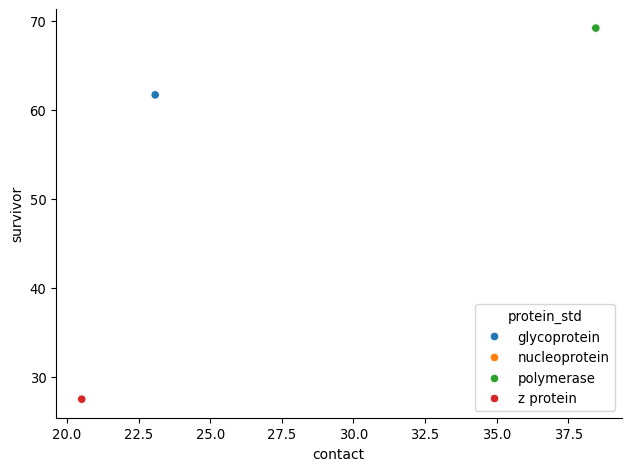

In [63]:
sns.scatterplot(
    data = df_plot, 
    x='contact', 
    y='survivor', 
    hue='protein_std'
)


# FDR < 0.05 -> open black circles
sig = df_plot.loc[df_plot['significant']]

ax.scatter(
    sig['contact'], 
    sig['survivor'], 
    s=90, 
    facecolors='none', 
    edgecolors='black', 
    linewidths=1.3, 
    label='FDR < 0.05', 
    zorder=10
)

#equality line
max_val = max(df_plot['contact'].max(), df_plot['survivor'].max())

ax.set_xlabel(
    f'Reactive ELISA-negative contacts (%)\n(n = {n_cont})',
    fontsize=12
)

ax.set_ylabel(
    f'Reactive Lassa survivors (%)\n(n = {n_surv})',
    fontsize=12
)

ax.set_title('')

sns.despine()

ax.legend(
    frameon=False,
    bbox_to_anchor=(0.98, 0.05),
    loc='lower right'
)

plt.tight_layout()
plt.show()

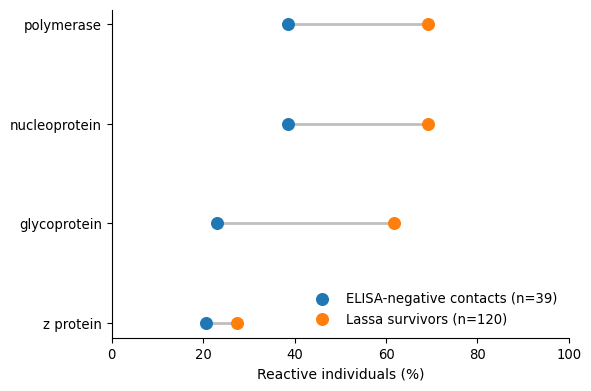

In [64]:
plot_df = df_plot.sort_values('survivor')

fig, ax = plt.subplots(figsize=(6, 4))

for _, row in plot_df.iterrows():
    ax.plot(
        [row['contact'], row['survivor']],
        [row['protein_std'], row['protein_std']],
        color='0.75',
        lw=2,
        zorder=1
    )

ax.scatter(
    plot_df['contact'],
    plot_df['protein_std'],
    s=70,
    label=f'ELISA-negative contacts (n={n_cont})',
    zorder=2
)

ax.scatter(
    plot_df['survivor'],
    plot_df['protein_std'],
    s=70,
    label=f'Lassa survivors (n={n_surv})',
    zorder=2
)

ax.set_xlabel('Reactive individuals (%)')
ax.set_ylabel('')

ax.set_xlim(0, 100)

ax.legend(frameon=False)

sns.despine()
plt.tight_layout()